In [1]:
# ASSIGNMENT NO. 4
# Predictive Models using Supervised Learning

# Name: Siddiqa Bagwan
# Roll No.: B24CE1093

In [6]:
import zipfile
import os

zip_file = "housing.zip"
with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall("housing_data")

print("Files extracted:")
print(os.listdir("housing_data"))

Files extracted:
['housing.csv']


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("housing_data/housing.csv")

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [13]:
print(df.shape)


(20640, 10)


In [14]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [15]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [16]:
df["total_bedrooms"] = df["total_bedrooms"].fillna(
    df["total_bedrooms"].median()
)

df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [19]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [17]:
df_encoded = pd.get_dummies(
    df,
    columns=["ocean_proximity"],
    drop_first=True
)

df_encoded = df_encoded.astype(float)

df_encoded.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0.0,0.0,1.0,0.0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0.0,0.0,1.0,0.0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0.0,0.0,1.0,0.0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0.0,0.0,1.0,0.0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0.0,0.0,1.0,0.0


In [18]:
X = df_encoded.drop("median_house_value", axis=1)
y = df_encoded["median_house_value"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (20640, 12)
Target: (20640,)


In [21]:
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [23]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [24]:
X_train_gd = np.c_[
    np.ones(X_train_scaled.shape[0]),
    X_train_scaled
]

X_test_gd = np.c_[
    np.ones(X_test_scaled.shape[0]),
    X_test_scaled
]

In [25]:
def linear_regression_gd(X, y, learning_rate=0.01, epochs=1000):

    weights = np.zeros(X.shape[1])
    n = len(y)

    cost_history = []

    for epoch in range(epochs):

        y_pred = X @ weights

        error = y_pred - y

        cost = (1 / (2 * n)) * np.sum(error ** 2)
        cost_history.append(cost)

        gradient = (1 / n) * (X.T @ error)

        weights = weights - learning_rate * gradient

    return weights, cost_history

In [26]:
weights_linear, cost_linear = linear_regression_gd(
    X_train_gd,
    y_train.values,
    learning_rate=0.01,
    epochs=1000
)

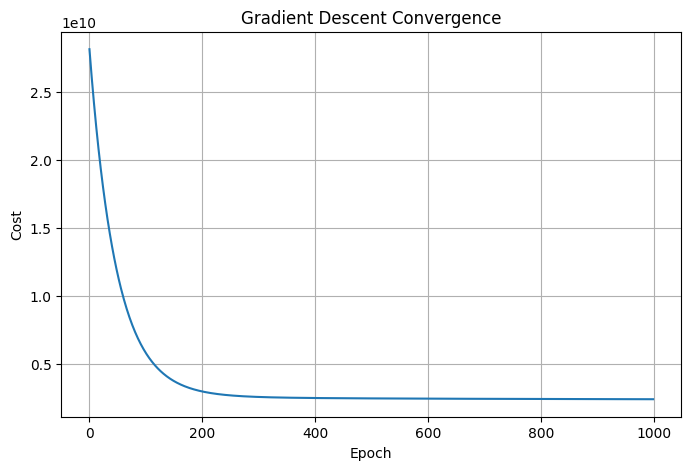

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(cost_linear)

plt.xlabel("Epoch")
plt.ylabel("Cost")
plt.title("Gradient Descent Convergence")

plt.grid()
plt.show()

In [28]:
y_pred_linear = X_test_gd @ weights_linear

mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression")
print("-----------------")
print("MAE  :", round(mae_linear, 2))
print("RMSE :", round(rmse_linear, 2))
print("R²   :", round(r2_linear, 4))

Linear Regression
-----------------
MAE  : 50842.38
RMSE : 70505.39
R²   : 0.6207


In [29]:
def ridge_regression_gd(X, y, learning_rate=0.01, epochs=1000, alpha=0.1):

    weights = np.zeros(X.shape[1])
    n = len(y)

    cost_history = []

    for epoch in range(epochs):

        y_pred = X @ weights

        error = y_pred - y

        regularization = (
            alpha / (2 * n)
        ) * np.sum(weights[1:] ** 2)

        cost = (
            (1 / (2 * n)) * np.sum(error ** 2)
            + regularization
        )

        cost_history.append(cost)

        gradient = (1 / n) * (X.T @ error)

        gradient[1:] += (
            alpha / n
        ) * weights[1:]

        weights = weights - learning_rate * gradient

    return weights, cost_history

In [30]:
weights_ridge, cost_ridge = ridge_regression_gd(
    X_train_gd,
    y_train.values,
    learning_rate=0.01,
    epochs=1000,
    alpha=0.1
)

In [31]:
y_pred_ridge = X_test_gd @ weights_ridge

mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression")
print("----------------")
print("MAE  :", round(mae_ridge, 2))
print("RMSE :", round(rmse_ridge, 2))
print("R²   :", round(r2_ridge, 4))

Ridge Regression
----------------
MAE  : 50842.4
RMSE : 70505.41
R²   : 0.6207


In [32]:
def lasso_regression_gd(X, y, learning_rate=0.01, epochs=1000, alpha=0.01):

    weights = np.zeros(X.shape[1])
    n = len(y)

    cost_history = []

    for epoch in range(epochs):

        y_pred = X @ weights

        error = y_pred - y

        regularization = (
            alpha / n
        ) * np.sum(np.abs(weights[1:]))

        cost = (
            (1 / (2 * n)) * np.sum(error ** 2)
            + regularization
        )

        cost_history.append(cost)

        gradient = (1 / n) * (X.T @ error)

        gradient[1:] += (
            alpha / n
        ) * np.sign(weights[1:])

        weights = weights - learning_rate * gradient

    return weights, cost_history

In [33]:
weights_lasso, cost_lasso = lasso_regression_gd(
    X_train_gd,
    y_train.values,
    learning_rate=0.01,
    epochs=1000,
    alpha=0.01
)

In [34]:
y_pred_lasso = X_test_gd @ weights_lasso

mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
r2_lasso = r2_score(y_test, y_pred_lasso)

print("Lasso Regression")
print("----------------")
print("MAE  :", round(mae_lasso, 2))
print("RMSE :", round(rmse_lasso, 2))
print("R²   :", round(r2_lasso, 4))

Lasso Regression
----------------
MAE  : 50842.38
RMSE : 70505.39
R²   : 0.6207


In [36]:
feature_names = ["Intercept"] + X.columns.tolist()

lasso_coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": weights_lasso
})

lasso_coefficients

,Feature,Coefficient
0,Intercept,207185.748885
1,longitude,-17550.034152
2,latitude,-16289.148923
3,housing_median_age,14596.413933
4,total_rooms,4285.295877
5,total_bedrooms,18853.555563
6,population,-32545.903132
7,households,15839.245146
8,median_income,72049.509594
9,ocean_proximity_INLAND,-30242.549350


In [37]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],

    "MAE": [
        mae_linear,
        mae_ridge,
        mae_lasso
    ],

    "RMSE": [
        rmse_linear,
        rmse_ridge,
        rmse_lasso
    ],

    "R² Score": [
        r2_linear,
        r2_ridge,
        r2_lasso
    ]
})

results

,Model,MAE,RMSE,R² Score
0,Linear Regression,50842.378586,70505.392201,0.620652
1,Ridge Regression,50842.398132,70505.406727,0.620652
2,Lasso Regression,50842.378586,70505.392201,0.620652


In [38]:
# Training predictions

y_train_pred_linear = X_train_gd @ weights_linear
y_train_pred_ridge = X_train_gd @ weights_ridge
y_train_pred_lasso = X_train_gd @ weights_lasso

train_r2 = [
    r2_score(y_train, y_train_pred_linear),
    r2_score(y_train, y_train_pred_ridge),
    r2_score(y_train, y_train_pred_lasso)
]

test_r2 = [
    r2_linear,
    r2_ridge,
    r2_lasso
]

bias_variance = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],
    "Training R²": train_r2,
    "Testing R²": test_r2
})

bias_variance

,Model,Training R²,Testing R²
0,Linear Regression,0.639304,0.620652
1,Ridge Regression,0.639304,0.620652
2,Lasso Regression,0.639304,0.620652


In [39]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = []

for train_index, val_index in cv.split(X):

    X_cv_train = X.iloc[train_index]
    X_cv_val = X.iloc[val_index]

    y_cv_train = y.iloc[train_index]
    y_cv_val = y.iloc[val_index]

    cv_scaler = StandardScaler()

    X_cv_train = cv_scaler.fit_transform(X_cv_train)
    X_cv_val = cv_scaler.transform(X_cv_val)

    model.fit(X_cv_train, y_cv_train)

    score = model.score(X_cv_val, y_cv_val)

    cv_scores.append(score)

print("5-Fold Cross-Validation R² Scores:")
print(np.round(cv_scores, 4))

print("\nMean Cross-Validation R²:",
      round(np.mean(cv_scores), 4))

5-Fold Cross-Validation R² Scores:
[0.6254 0.6513 0.6475 0.6744 0.6179]

Mean Cross-Validation R²: 0.6433
